# Лабораторна робота №3

## Нейронні мережі для класифікації

Мета роботи: дослідити навчання нейронних мереж на табличних даних, зображеннях і текстах за допомогою PyTorch. Порівняти моделі за якістю, стабільністю та швидкістю збіжності. Усі експерименти виконуються локально.

In [1]:
from pathlib import Path
from collections import Counter
from IPython.display import display, Markdown
import copy
import os
import random
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image, ImageFile
from sklearn.datasets import fetch_20newsgroups
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset
from torchvision import models, transforms

ImageFile.LOAD_TRUNCATED_IMAGES = True
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu':
    torch.set_num_threads(min(4, torch.get_num_threads()))

# Папку з даними можна задати через змінну середовища LAB_DATA_ROOT.
folders = [Path(os.environ['LAB_DATA_ROOT'])] if os.environ.get('LAB_DATA_ROOT') else []
folders += [Path.cwd(), Path.cwd() / 'lab1', Path.cwd().parent / 'lab1',
            Path(r'C:\study\5 курс\аналіз даних\lab1')]
ROOT = next((folder for folder in folders if (folder / 'data.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Не знайдено data.csv. Покладіть його в папку з ноутбуком/lab1 або задайте LAB_DATA_ROOT.')
print('Робоча папка:', ROOT)
print('Пристрій:', DEVICE)
print('PyTorch:', torch.__version__)


Робоча папка: C:\study\5 курс\аналіз даних\lab1
Пристрій: cpu
PyTorch: 2.8.0+cpu


## 1. Повнозв’язана нейронна мережа

Використано дані про успішність студентів із лабораторної №1 (4424 записи, класи Dropout, Enrolled, Graduate). Дані поділено на train, validation і test у співвідношенні приблизно 68/12/20. Категоріальні ознаки закодовано, числові стандартизовано за параметрами лише тренувальної вибірки. Для зіставлення з MLP використано SVM і Random Forest із лабораторної №1.


In [2]:
frame = pd.read_csv(ROOT / 'data.csv', sep=';')
frame.columns = (frame.columns.str.strip()
                 .str.replace('Curricular units ', '', regex=False)
                 .str.replace('Nacionality', 'Nationality', regex=False))
labels_tab = ['Dropout', 'Enrolled', 'Graduate']
nominal = ['Marital status', 'Application mode', 'Course', 'Previous qualification',
           'Nationality', "Mother's qualification", "Father's qualification",
           "Mother's occupation", "Father's occupation"]
missing_columns = set(nominal + ['Target']).difference(frame.columns)
if missing_columns:
    raise ValueError(f'Недостатньо стовпців: {sorted(missing_columns)}')

y_tab = frame['Target'].map({value: index for index, value in enumerate(labels_tab)})
if y_tab.isna().any():
    raise ValueError('У стовпці Target виявлено невідомі класи')
x_tab = frame.drop(columns='Target')
x_dev, x_test_raw, y_dev, y_test_tab = train_test_split(
    x_tab, y_tab.astype(int), test_size=0.2, random_state=SEED, stratify=y_tab)
x_train_raw, x_val_raw, y_train_tab, y_val_tab = train_test_split(
    x_dev, y_dev, test_size=0.15, random_state=SEED, stratify=y_dev)

rare = {}
for column in nominal:
    frequencies = x_train_raw[column].value_counts()
    rare[column] = set(frequencies[frequencies < max(1, int(0.01 * len(x_train_raw)))].index)

def onehot(part):
    table = part.copy()
    for column in nominal:
        table[column] = table[column].where(~table[column].isin(rare[column]), -1).astype(str)
    return pd.get_dummies(table, columns=nominal, dtype=np.float32).astype(np.float32)

x_train = onehot(x_train_raw)
x_val = onehot(x_val_raw).reindex(columns=x_train.columns, fill_value=0)
x_test = onehot(x_test_raw).reindex(columns=x_train.columns, fill_value=0)
continuous = [column for column in x_train.columns
              if column in x_tab.columns and column not in nominal and x_train_raw[column].nunique() > 2]
scaler = StandardScaler()
x_train.loc[:, continuous] = scaler.fit_transform(x_train.loc[:, continuous]).astype(np.float32)
for table in (x_val, x_test):
    table.loc[:, continuous] = scaler.transform(table.loc[:, continuous]).astype(np.float32)

print('Кількість записів:', len(frame))
print('Навчальна вибірка:', len(x_train))
print('Валідаційна вибірка:', len(x_val))
print('Тестова вибірка:', len(x_test))
print('Кількість ознак після кодування:', x_train.shape[1])

Кількість записів: 4424
Навчальна вибірка: 3008
Валідаційна вибірка: 531
Тестова вибірка: 885
Кількість ознак після кодування: 109


Найкраща епоха: 8
Test accuracy: 0.7684 Час, с: 1.7


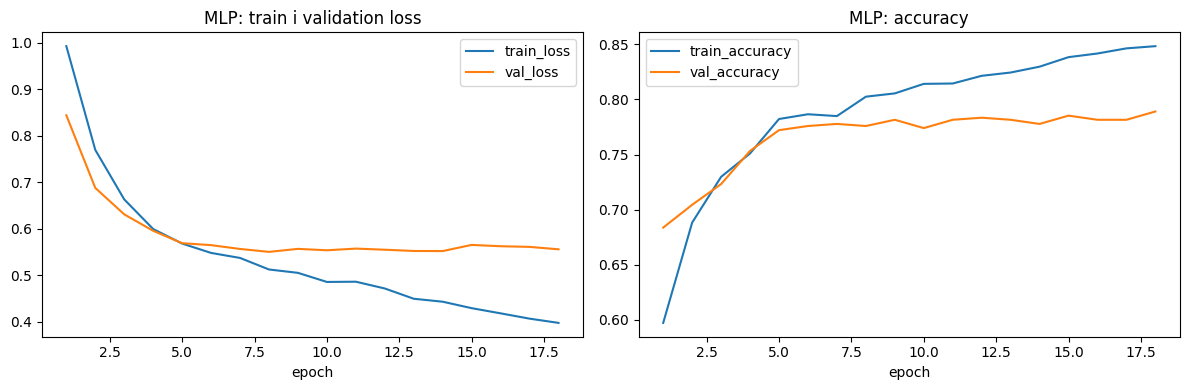

In [3]:
class TabularMLP(nn.Module):
    def __init__(self, features):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(features, 128), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(64, len(labels_tab)))

    def forward(self, x):
        return self.layers(x)

def tabular_loader(features, labels, shuffle=False):
    dataset = TensorDataset(torch.tensor(features.to_numpy(dtype=np.float32)),
                            torch.tensor(labels.to_numpy(dtype=np.int64)))
    return DataLoader(dataset, batch_size=128, shuffle=shuffle, num_workers=0)

train_tab = tabular_loader(x_train, y_train_tab, True)
val_tab = tabular_loader(x_val, y_val_tab)
test_tab = tabular_loader(x_test, y_test_tab)

def tabular_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total, hits, size = 0.0, 0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits = model(inputs)
            loss = nn.functional.cross_entropy(logits, targets)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        total += loss.item() * len(targets)
        hits += (logits.argmax(1) == targets).sum().item()
        size += len(targets)
    return total / size, hits / size

mlp = TabularMLP(x_train.shape[1]).to(DEVICE)
optimizer = torch.optim.AdamW(mlp.parameters(), lr=0.001, weight_decay=0.0001)
records, best, state, patience = [], float('inf'), None, 0
start = time.perf_counter()
for epoch in range(1, 61):
    train_loss, train_accuracy = tabular_epoch(mlp, train_tab, optimizer)
    val_loss, val_accuracy = tabular_epoch(mlp, val_tab)
    records.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                        train_accuracy=train_accuracy, val_accuracy=val_accuracy))
    if val_loss < best - 0.0001:
        best, state, patience = val_loss, copy.deepcopy(mlp.state_dict()), 0
    else:
        patience += 1
    if patience >= 10:
        break
mlp.load_state_dict(state)
mlp_time = time.perf_counter() - start
history_tab = pd.DataFrame(records).set_index('epoch')
loss_tab, acc_tab = tabular_epoch(mlp, test_tab)
print('Найкраща епоха:', history_tab.val_loss.idxmin())
print('Test accuracy:', round(acc_tab, 4), 'Час, с:', round(mlp_time, 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
history_tab[['train_loss', 'val_loss']].plot(ax=axes[0], title='MLP: train і validation loss')
history_tab[['train_accuracy', 'val_accuracy']].plot(ax=axes[1], title='MLP: accuracy')
plt.tight_layout()
plt.show()

In [4]:
def tabular_predictions(model, loader):
    result = []
    model.eval()
    with torch.no_grad():
        for features, _ in loader:
            result.extend(model(features.to(DEVICE)).argmax(1).cpu().numpy())
    return np.asarray(result)

prediction_mlp = tabular_predictions(mlp, test_tab)
comparison_tab = [{'Модель': 'MLP',
                   'Test accuracy': accuracy_score(y_test_tab, prediction_mlp),
                   'Macro F1': f1_score(y_test_tab, prediction_mlp, average='macro')}]
for name, estimator in [('SVM', SVC(C=100, gamma=0.001)),
                        ('Random Forest', RandomForestClassifier(random_state=SEED, n_jobs=-1))]:
    # Всі три моделі отримують одну й ту саму train-вибірку.
    estimator.fit(x_train, y_train_tab)
    predicted = estimator.predict(x_test)
    comparison_tab.append({'Модель': name,
                           'Test accuracy': accuracy_score(y_test_tab, predicted),
                           'Macro F1': f1_score(y_test_tab, predicted, average='macro')})
result_tab = pd.DataFrame(comparison_tab).set_index('Модель')
display(result_tab.round(4))
print(classification_report(y_test_tab, prediction_mlp, target_names=labels_tab, zero_division=0))

best_epoch_tab = int(history_tab.val_loss.idxmin())
end_gap_tab = float(history_tab.train_loss.iloc[-1] - history_tab.val_loss.iloc[-1])
start_gap_tab = float(history_tab.train_loss.iloc[0] - history_tab.val_loss.iloc[0])
leader_tab = result_tab['Test accuracy'].idxmax()
mlp_acc = result_tab.loc['MLP', 'Test accuracy']
mlp_f1 = result_tab.loc['MLP', 'Macro F1']
analysis_tab = (
    f'**Аналіз MLP.** Найменший validation loss отримано на епосі {best_epoch_tab}; '
    f'на тесті accuracy = {mlp_acc:.2%}, macro F1 = {mlp_f1:.3f}. '
    f'Найвища тестова accuracy серед трьох моделей — у {leader_tab}. '
)
if history_tab.val_loss.iloc[-1] > history_tab.val_loss.min() + 0.005:
    analysis_tab += ('Після найкращої епохи validation loss зростає, тоді як train loss '
                     'зменшується: помітні ознаки перенавчання. Раннє зупинення '
                     'й відновлення найкращих ваг обмежують цей ефект.')
else:
    analysis_tab += ('Криві наприкінці зближуються недостатньо швидко; істотного '
                     'зростання validation loss після мінімуму немає, але розрив між '
                     'train і validation слід контролювати.')
display(Markdown(analysis_tab))


,Test accuracy,Macro F1
Модель,,
MLP,0.7684,0.7010
SVM,0.7593,0.6905
Random Forest,0.7650,0.6664


              precision    recall  f1-score   support

     Dropout       0.81      0.75      0.78       284
    Enrolled       0.54      0.42      0.48       159
    Graduate       0.80      0.91      0.85       442

    accuracy                           0.77       885
   macro avg       0.72      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885



**Аналіз MLP.** Найменший validation loss отримано на епосі 8; на тесті accuracy = 76.84%, macro F1 = 0.701. Найвища тестова accuracy серед трьох моделей — у MLP. Після найкращої епохи validation loss зростає, тоді як train loss зменшується: помітні ознаки перенавчання. Раннє зупинення й відновлення найкращих ваг обмежують цей ефект.

## 2. Класифікація зображень

Для задачі класифікації котів і собак обрано **Oxford-IIIT Pet**: оригінальний набір охоплює 37 порід тварин, які об'єднано у два класи. Для експерименту використовуються тільки доступні локально файли із папки images та анотації trainval.txt/test.txt; фактичну кількість зображень кожного класу виведено нижче. Порівнюються власна CNN з трьома згортковими шарами та **MobileNetV3-Small з вагами ImageNet**. Тестовий набір відокремлений і не використовується під час навчання.


Локально доступні зображення: 2881
Train: 1151 Validation: 288 Test: 1442
Кількість порід: 37
Коти і собаки: {0: 906, 1: 1975}


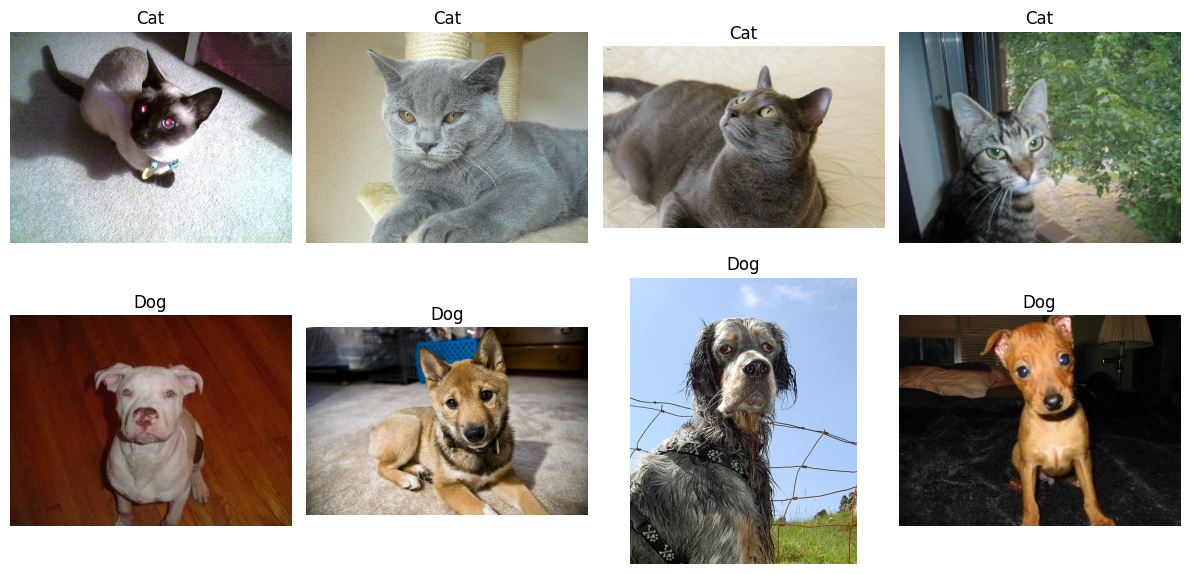

In [5]:
image_candidates = [ROOT / 'images', ROOT / 'images' / 'images',
                    ROOT / 'oxford-iiit-pet' / 'images',
                    ROOT / 'datasets' / 'oxford-iiit-pet' / 'images']
annotation_candidates = [ROOT / 'annotations', ROOT / 'annotations' / 'annotations',
                         ROOT / 'oxford-iiit-pet' / 'annotations',
                         ROOT / 'datasets' / 'oxford-iiit-pet' / 'annotations']
IMAGE_DIR = next((folder for folder in image_candidates if folder.is_dir() and any(folder.glob('*.jpg'))), None)
ANNOT_DIR = next((folder for folder in annotation_candidates
                  if (folder / 'trainval.txt').is_file() and (folder / 'test.txt').is_file()), None)
if IMAGE_DIR is None or ANNOT_DIR is None:
    raise FileNotFoundError('Не знайдено локальні папки images або annotations з файлами trainval.txt і test.txt.')

def pet_split(filename):
    entries = []
    for line in (ANNOT_DIR / filename).read_text(encoding='utf-8').splitlines():
        fields = line.split()
        if len(fields) < 4:
            continue
        stem, breed, species = fields[0], int(fields[1]) - 1, int(fields[2]) - 1
        location = IMAGE_DIR / (stem + '.jpg')
        if location.is_file():
            try:
                with Image.open(location) as image:
                    image.verify()
                entries.append((location, species, breed))
            except (OSError, ValueError):
                pass
    return entries

pet_dev = pet_split('trainval.txt')
pet_hold = pet_split('test.txt')
all_pet = pet_dev + pet_hold
if len(set(item[1] for item in all_pet)) != 2:
    raise ValueError('Локальні зображення не містять обох класів: котів і собак.')
if len(set(item[1] for item in pet_dev)) != 2 or len(set(item[1] for item in pet_hold)) != 2:
    raise ValueError('Для обох класів потрібні файли і в trainval.txt, і в test.txt.')
if min(Counter(item[1] for item in pet_dev).values()) < 3:
    raise ValueError('Недостатньо trainval-зображень для stratified train/validation split.')
if set(path for path, _, _ in pet_dev) & set(path for path, _, _ in pet_hold):
    raise ValueError('Train і test перетинаються; перевірте анотації Oxford-IIIT Pet.')

train_ids, val_ids = train_test_split(np.arange(len(pet_dev)), test_size=0.2,
                                     stratify=[item[1] for item in pet_dev], random_state=SEED)
pet_train_entries = [pet_dev[index] for index in train_ids]
pet_val_entries = [pet_dev[index] for index in val_ids]
IMAGE_SIZE = 96
image_train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(), transforms.ToTensor()])
image_eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])

class PetLocalDataset(Dataset):
    def __init__(self, items, transformation, target='species'):
        self.items = items
        self.transformation = transformation
        self.target = target

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        path, species, breed = self.items[index]
        with Image.open(path) as image:
            features = self.transformation(image.convert('RGB'))
        return features, species if self.target == 'species' else breed

pet_train = PetLocalDataset(pet_train_entries, image_train_transform)
pet_train_eval = PetLocalDataset(pet_train_entries, image_eval_transform)
pet_val = PetLocalDataset(pet_val_entries, image_eval_transform)
pet_test = PetLocalDataset(pet_hold, image_eval_transform)
print('Локально доступні зображення:', len(all_pet))
print('Train:', len(pet_train), 'Validation:', len(pet_val), 'Test:', len(pet_test))
print('Кількість порід:', len(set(item[2] for item in all_pet)))
print('Коти і собаки:', dict(Counter(item[1] for item in all_pet)))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for species in range(2):
    examples = [item for item in pet_train_entries if item[1] == species][:4]
    for axis, (path, _, _) in zip(axes[species], examples):
        with Image.open(path) as image:
            axis.imshow(image.convert('RGB'))
        axis.set_title('Cat' if species == 0 else 'Dog')
        axis.axis('off')
plt.tight_layout()
plt.show()


### CNN з нуля

Мережа складається із трьох згорткових блоків, адаптивного пулінгу та повнозв’язаного класифікатора. Навчання виконується на train, вибір епохи за validation loss.

In [6]:
IMAGE_BATCH = 32
IMAGE_EPOCHS = 8
train_img_loader = DataLoader(pet_train, batch_size=IMAGE_BATCH, shuffle=True, num_workers=0)
val_img_loader = DataLoader(pet_val, batch_size=IMAGE_BATCH, num_workers=0)
test_img_loader = DataLoader(pet_test, batch_size=IMAGE_BATCH, num_workers=0)

class ImageCNN(nn.Module):
    def __init__(self, classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 24, 3, padding=1), nn.BatchNorm2d(24), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(24, 48, 3, padding=1), nn.BatchNorm2d(48), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(48, 96, 3, padding=1), nn.BatchNorm2d(96), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
                                        nn.Dropout(0.3), nn.Linear(96, classes))

    def forward(self, features):
        return self.classifier(self.features(features))

def image_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        # Під час навчання класифікатора статистики заморожених BatchNorm не оновлюються.
        for layer in model.modules():
            if isinstance(layer, nn.modules.batchnorm._BatchNorm):
                params = list(layer.parameters(recurse=False))
                if params and not any(param.requires_grad for param in params):
                    layer.eval()
    total, correct, size = 0.0, 0, 0
    for features, targets in loader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        with torch.set_grad_enabled(training):
            prediction = model(features)
            loss = nn.functional.cross_entropy(prediction, targets)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        total += loss.item() * len(targets)
        correct += (prediction.argmax(1) == targets).sum().item()
        size += len(targets)
    return total / size, correct / size

def fit_image(model, train_loader, val_loader, epochs, lr, train_features=None):
    model.to(DEVICE)
    if train_features is not None:
        model.features.requires_grad_(train_features)
    optimizer = torch.optim.AdamW((param for param in model.parameters() if param.requires_grad),
                                   lr=lr, weight_decay=0.0001)
    history, best, weights = [], float('inf'), None
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = image_epoch(model, train_loader, optimizer)
        val_loss, val_acc = image_epoch(model, val_loader)
        history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                            train_accuracy=train_acc, val_accuracy=val_acc))
        if val_loss < best:
            best, weights = val_loss, copy.deepcopy(model.state_dict())
        print(f'Епоха {epoch}: train {train_loss:.4f}, validation {val_loss:.4f}, accuracy {val_acc:.4f}')
    model.load_state_dict(weights)
    return pd.DataFrame(history).set_index('epoch'), time.perf_counter() - start

def image_predictions(model, loader):
    model.eval()
    truth, prediction = [], []
    with torch.no_grad():
        for features, target in loader:
            output = model(features.to(DEVICE)).argmax(1).cpu().numpy()
            truth.extend(target.numpy())
            prediction.extend(output)
    return np.asarray(truth), np.asarray(prediction)

torch.manual_seed(SEED)
image_scratch = ImageCNN()
history_scratch, seconds_scratch = fit_image(
    image_scratch, train_img_loader, val_img_loader, IMAGE_EPOCHS, 0.001)


Епоха 1: train 0.6207, validation 0.6396, accuracy 0.6562
Епоха 2: train 0.5954, validation 0.6240, accuracy 0.6562
Епоха 3: train 0.5958, validation 0.6137, accuracy 0.6632
Епоха 4: train 0.5848, validation 0.6143, accuracy 0.6632
Епоха 5: train 0.5979, validation 0.6097, accuracy 0.6771
Епоха 6: train 0.5920, validation 0.6091, accuracy 0.7014
Епоха 7: train 0.5744, validation 0.6013, accuracy 0.6910
Епоха 8: train 0.5793, validation 0.6281, accuracy 0.6528


### Pretrained CNN: MobileNetV3-Small

Використано MobileNetV3-Small із готовими вагами, навченими на ImageNet. Останній лінійний шар змінено на два виходи. Спочатку навчається новий класифікатор за заморожених ознак, далі розморожуються останні три блоки ознак та виконується донавчання з меншою швидкістю навчання. Для цієї моделі зображення нормалізуються за статистиками ImageNet. Під час першого запуску ваги моделі завантажуються із сервера PyTorch і кешуються локально.


In [7]:
# Окремі перетворення для pretrained моделі (ImageNet normalization).
PRETRAINED_SIZE = 160
image_pre_train_transform = transforms.Compose([
    transforms.Resize((PRETRAINED_SIZE, PRETRAINED_SIZE)),
    transforms.RandomHorizontalFlip(), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
image_pre_eval_transform = transforms.Compose([
    transforms.Resize((PRETRAINED_SIZE, PRETRAINED_SIZE)), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
pet_train_pre = PetLocalDataset(pet_train_entries, image_pre_train_transform)
pet_val_pre = PetLocalDataset(pet_val_entries, image_pre_eval_transform)
pet_test_pre = PetLocalDataset(pet_hold, image_pre_eval_transform)
train_img_loader_pre = DataLoader(pet_train_pre, batch_size=IMAGE_BATCH, shuffle=True, num_workers=0)
val_img_loader_pre = DataLoader(pet_val_pre, batch_size=IMAGE_BATCH, num_workers=0)
test_img_loader_pre = DataLoader(pet_test_pre, batch_size=IMAGE_BATCH, num_workers=0)

MOBILENET_WEIGHTS = models.MobileNet_V3_Small_Weights.DEFAULT

def make_transfer_model():
    try:
        model = models.mobilenet_v3_small(weights=MOBILENET_WEIGHTS)
    except Exception as error:
        raise RuntimeError('Не вдалося завантажити готові ваги MobileNetV3. Перевірте інтернет або кеш PyTorch.') from error
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, 2)
    return model

torch.manual_seed(SEED)
transfer_cnn = make_transfer_model()
# Етап 1: заморожені ознаки, навчається тільки класифікатор.
history_head, seconds_head = fit_image(
    transfer_cnn, train_img_loader_pre, val_img_loader_pre,
    epochs=3, lr=0.001, train_features=False)
head_state = copy.deepcopy(transfer_cnn.state_dict())

# Етап 2: донавчання останніх трьох блоків ознак.
transfer_cnn.features.requires_grad_(False)
for block in list(transfer_cnn.features.children())[-3:]:
    block.requires_grad_(True)
history_finetune, seconds_finetune = fit_image(
    transfer_cnn, train_img_loader_pre, val_img_loader_pre,
    epochs=5, lr=0.0001, train_features=None)
finetune_state = copy.deepcopy(transfer_cnn.state_dict())
if history_head.val_loss.min() <= history_finetune.val_loss.min():
    transfer_cnn.load_state_dict(head_state)
else:
    transfer_cnn.load_state_dict(finetune_state)
history_finetune.index += len(history_head)
history_transfer = pd.concat([history_head, history_finetune])
seconds_transfer = seconds_head + seconds_finetune
print('Час навчання класифікатора, с:', round(seconds_head, 1))
print('Час донавчання ознак, с:', round(seconds_finetune, 1))
print('Сумарний час навчання MobileNetV3 на Oxford-IIIT Pet, с:', round(seconds_transfer, 1))


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to C:\Users\Asus/.cache\torch\hub\checkpoints\mobilenet_v3_small-047dcff4.pth


100%|█████████████████████████████████████████████████████████████████████████████| 9.83M/9.83M [00:00<00:00, 11.3MB/s]


Епоха 1: train 0.2485, validation 0.1381, accuracy 0.9514
Епоха 2: train 0.1163, validation 0.1463, accuracy 0.9618
Епоха 3: train 0.0615, validation 0.1436, accuracy 0.9410
Епоха 1: train 0.1799, validation 0.2353, accuracy 0.9097
Епоха 2: train 0.1250, validation 0.1704, accuracy 0.9306
Епоха 3: train 0.0764, validation 0.1374, accuracy 0.9514
Епоха 4: train 0.0686, validation 0.1502, accuracy 0.9410
Епоха 5: train 0.0384, validation 0.1393, accuracy 0.9479
Час навчання класифікатора, с: 28.0
Час донавчання ознак, с: 51.9
Сумарний час навчання MobileNetV3 на Oxford-IIIT Pet, с: 79.8


,accuracy,macro_F1,best_epoch,best_val_loss,training_seconds
Модель,,,,,
CNN з нуля,0.6928,0.5784,7,0.6013,98.8666
MobileNetV3 (ImageNet),0.9376,0.9256,6,0.1374,79.8473


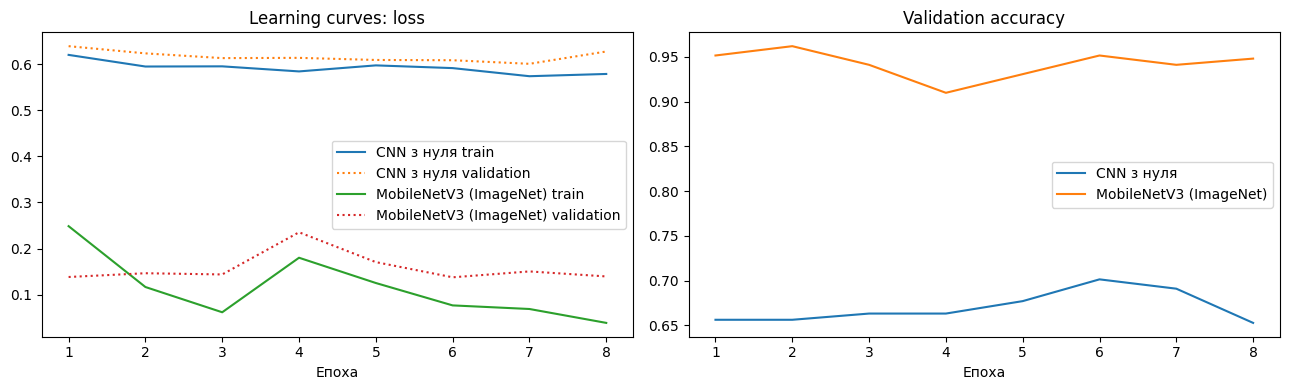

**Порівняння CNN.** На тестовій вибірці найвища accuracy — у MobileNetV3 (ImageNet), найвищий macro F1 — у MobileNetV3 (ImageNet). Різниця accuracy (MobileNetV3 мінус CNN з нуля) = +24.48 в. п. Найкращий validation loss: CNN — епоха 7, MobileNetV3 — 6. Час навчання на Oxford-IIIT Pet: 98.9 с і 79.8 с відповідно (без урахування початкового навчання ImageNet). У CNN з нуля наприкінці learning curve є зростання validation loss. Обидві моделі оцінено на однакових зображеннях; відмінність розміру входу та нормалізації пов’язана з вимогами pretrained архітектури.

In [8]:
image_rows = []
for title, model, history, seconds, loader in [
    ('CNN з нуля', image_scratch, history_scratch, seconds_scratch, test_img_loader),
    ('MobileNetV3 (ImageNet)', transfer_cnn, history_transfer, seconds_transfer, test_img_loader_pre)]:
    truth_img, predicted_img = image_predictions(model, loader)
    image_rows.append(dict(Модель=title,
                           accuracy=accuracy_score(truth_img, predicted_img),
                           macro_F1=f1_score(truth_img, predicted_img, average='macro'),
                           best_epoch=int(history.val_loss.idxmin()),
                           best_val_loss=float(history.val_loss.min()),
                           training_seconds=seconds))
result_img = pd.DataFrame(image_rows).set_index('Модель')
display(result_img.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for title, history in [('CNN з нуля', history_scratch),
                       ('MobileNetV3 (ImageNet)', history_transfer)]:
    axes[0].plot(history.index, history.train_loss, label=title + ' train')
    axes[0].plot(history.index, history.val_loss, linestyle=':', label=title + ' validation')
    axes[1].plot(history.index, history.val_accuracy, label=title)
axes[0].set_title('Learning curves: loss')
axes[1].set_title('Validation accuracy')
for axis in axes:
    axis.set_xlabel('Епоха')
    axis.legend()
plt.tight_layout()
plt.show()

better_acc_img = result_img.accuracy.idxmax()
better_f1_img = result_img.macro_F1.idxmax()
acc_diff_img = (result_img.loc['MobileNetV3 (ImageNet)', 'accuracy'] -
                result_img.loc['CNN з нуля', 'accuracy']) * 100
image_analysis = (f'**Порівняння CNN.** На тестовій вибірці найвища accuracy — у '
                  f'{better_acc_img}, найвищий macro F1 — у {better_f1_img}. '
                  f'Різниця accuracy (MobileNetV3 мінус CNN з нуля) = {acc_diff_img:+.2f} в. п. '
                  f'Найкращий validation loss: CNN — епоха '
                  f'{result_img.loc["CNN з нуля", "best_epoch"]:.0f}, MobileNetV3 — '
                  f'{result_img.loc["MobileNetV3 (ImageNet)", "best_epoch"]:.0f}. '
                  f'Час навчання на Oxford-IIIT Pet: '
                  f'{seconds_scratch:.1f} с і {seconds_transfer:.1f} с відповідно '
                  '(без урахування початкового навчання ImageNet). ')
if history_scratch.val_loss.iloc[-1] > history_scratch.val_loss.min() + 0.005:
    image_analysis += 'У CNN з нуля наприкінці learning curve є зростання validation loss. '
if history_transfer.val_loss.iloc[-1] > history_transfer.val_loss.min() + 0.005:
    image_analysis += 'У донавченій MobileNetV3 після мінімуму validation loss теж спостерігається погіршення. '
image_analysis += ('Обидві моделі оцінено на однакових зображеннях; відмінність розміру входу '
                   'та нормалізації пов’язана з вимогами pretrained архітектури.')
display(Markdown(image_analysis))


### Вплив кількості тренувальних зображень

Порівнюється якість моделей після двох епох навчання на 25 % і 100 % тієї самої train-вибірки. Для pretrained MobileNetV3 використовуються **одні й ті самі готові ваги ImageNet** у кожному експерименті, а її ознаки заморожені. Валідаційний набір незмінний. Так можна оцінити, наскільки перенесення навчання допомагає за меншої кількості розмічених зображень; порівняння часу стосується лише навчання на Oxford-IIIT Pet.


Епоха 1: train 0.6473, validation 0.8210, accuracy 0.3160
Епоха 2: train 0.5959, validation 0.7280, accuracy 0.3750
Епоха 1: train 0.3827, validation 0.2329, accuracy 0.8854
Епоха 2: train 0.1545, validation 0.2110, accuracy 0.9097
Епоха 1: train 0.6207, validation 0.6396, accuracy 0.6562
Епоха 2: train 0.5954, validation 0.6240, accuracy 0.6562
Епоха 1: train 0.2485, validation 0.1381, accuracy 0.9514
Епоха 2: train 0.1163, validation 0.1463, accuracy 0.9618


,Частка,Модель,Validation accuracy,Validation loss,"Час, с"
0,25%,CNN з нуля,0.3750,0.7280,8.3368
1,25%,MobileNetV3 (ImageNet),0.9097,0.2110,6.5261
2,100%,CNN з нуля,0.6562,0.6240,23.8535
3,100%,MobileNetV3 (ImageNet),0.9514,0.1381,17.5013


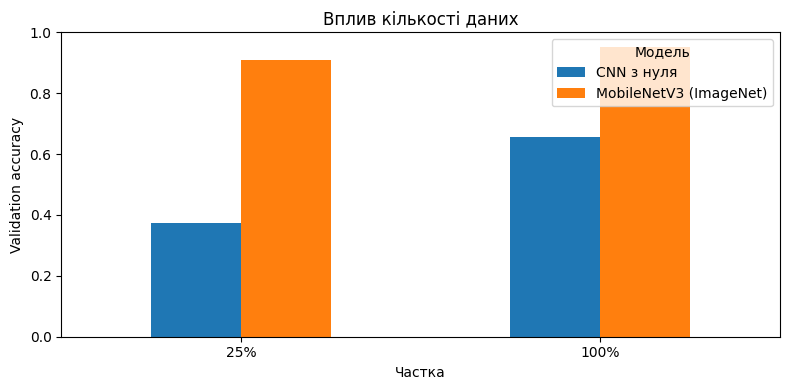

CNN з нуля: зміна validation accuracy від 25% до 100% = +28.12 в. п.
MobileNetV3 (ImageNet): зміна validation accuracy від 25% до 100% = +4.17 в. п.


In [9]:
fraction_rows = []
for fraction in [0.25, 1.0]:
    all_indices = np.arange(len(pet_train_entries))
    indices = (train_test_split(all_indices, train_size=fraction, random_state=SEED,
              stratify=[item[1] for item in pet_train_entries])[0]
              if fraction < 1.0 else all_indices)
    for transferred in [False, True]:
        torch.manual_seed(SEED)
        if transferred:
            model = make_transfer_model()
            local_train = DataLoader(Subset(pet_train_pre, indices.tolist()),
                                     batch_size=IMAGE_BATCH, shuffle=True, num_workers=0)
            valid = val_img_loader_pre
        else:
            model = ImageCNN()
            local_train = DataLoader(Subset(pet_train, indices.tolist()),
                                     batch_size=IMAGE_BATCH, shuffle=True, num_workers=0)
            valid = val_img_loader
        log, elapsed = fit_image(model, local_train, valid, epochs=2,
                                 lr=0.001, train_features=not transferred)
        best_epoch = int(log.val_loss.idxmin())
        fraction_rows.append({'Частка': f'{fraction:.0%}',
                              'Модель': 'MobileNetV3 (ImageNet)' if transferred else 'CNN з нуля',
                              'Validation accuracy': float(log.loc[best_epoch, 'val_accuracy']),
                              'Validation loss': float(log.loc[best_epoch, 'val_loss']),
                              'Час, с': elapsed})
size_img = pd.DataFrame(fraction_rows)
display(size_img.round(4))
size_img.pivot(index='Частка', columns='Модель', values='Validation accuracy').reindex(
    ['25%', '100%']).plot(kind='bar', rot=0, ylim=(0, 1), figsize=(8, 4),
                         title='Вплив кількості даних')
plt.ylabel('Validation accuracy')
plt.tight_layout()
plt.show()
for model_name in size_img['Модель'].unique():
    subset = size_img.set_index(['Модель', 'Частка']).loc[model_name]
    gain = (subset.loc['100%', 'Validation accuracy'] - subset.loc['25%', 'Validation accuracy']) * 100
    print(f'{model_name}: зміна validation accuracy від 25% до 100% = {gain:+.2f} в. п.')


## 3. Нейронні мережі для класифікації текстів

Використано 20 Newsgroups із лабораторної №2: три тематичні категорії **comp.graphics, rec.sport.hockey, sci.space**. Після очищення текстів виконуються токенізація, побудова словника за train, перетворення слів на індекси та padding/truncation до 200 токенів. Порівнюються дві BiLSTM однакової архітектури: із випадково ініціалізованими векторами слів і з готовими **GloVe 50d**.


In [10]:
categories = ['comp.graphics', 'rec.sport.hockey', 'sci.space']
try:
    local_news = fetch_20newsgroups(subset='all', categories=categories,
                                    remove=('headers', 'footers', 'quotes'),
                                    shuffle=True, random_state=SEED,
                                    download_if_missing=True)
except OSError as error:
    raise FileNotFoundError('Не вдалося отримати 20 Newsgroups. Потрібен локальний кеш або доступ до інтернету.') from error
texts = pd.DataFrame({'text': local_news.data,
                      'label': np.asarray(local_news.target_names)[local_news.target]})
stopwords = set(ENGLISH_STOP_WORDS) | {
    'like', 'know', 'think', 'just', 'don', 'does', 'doesn', 'didn', 'did',
    'isn', 'use', 'used', 'using', 'good', 'people', 'time', 'way', 'really',
    'want', 'need', 'make', 'say', 'said', 'going', 'thing', 'things', 'lot',
    'sure', 'thanks', 'right', 'got', 'let', 'edu', 'com'}

def clean_text(document):
    document = document.lower()
    document = re.sub(r'\S+@\S+|http\S+|www\.\S+|\S+\.(?:com|edu|net|org|gov)\b\S*', ' ', document)
    document = re.sub(r'[^a-z\s]', ' ', document)
    return ' '.join(token for token in document.split()
                    if token not in stopwords and len(token) > 2)

texts['clean_text'] = texts.text.map(clean_text)
texts = texts[texts.clean_text.str.split().str.len() >= 3].reset_index(drop=True)
texts['target'] = texts.label.map({label: number for number, label in enumerate(categories)})
train_val_text, test_text = train_test_split(texts, test_size=0.2,
                                              stratify=texts.target, random_state=SEED)
train_text, val_text = train_test_split(train_val_text, test_size=0.15,
                                        stratify=train_val_text.target, random_state=SEED)
print('Train:', len(train_text), 'Validation:', len(val_text), 'Test:', len(test_text))
display(texts.label.value_counts().rename('Кількість').to_frame())

Train: 1931 Validation: 341 Test: 569


,Кількість
label,
rec.sport.hockey,958
sci.space,947
comp.graphics,936


Словник: 11994 Довжина послідовностей: 200
Матриця текстів: (1931, 200)


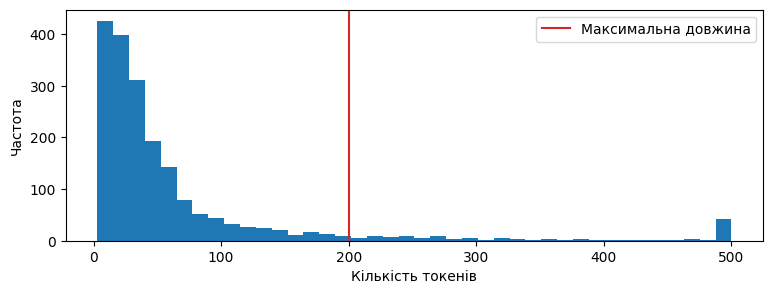

In [11]:
def tokenize(document):
    return document.split()

train_tokens = train_text.clean_text.map(tokenize)
val_tokens = val_text.clean_text.map(tokenize)
test_tokens = test_text.clean_text.map(tokenize)
MAX_LENGTH = 200
VOCAB_MIN_FREQUENCY = 2
frequencies = Counter(token for document in train_tokens for token in document)
words = ['<pad>', '<unk>'] + [token for token, frequency in frequencies.most_common()
                             if frequency >= VOCAB_MIN_FREQUENCY]
vocabulary = {token: number for number, token in enumerate(words)}
PAD, UNK = vocabulary['<pad>'], vocabulary['<unk>']

def encode_documents(documents):
    sequence = np.full((len(documents), MAX_LENGTH), PAD, dtype=np.int64)
    lengths = np.ones(len(documents), dtype=np.int64)
    for row, tokens in enumerate(documents):
        indices = [vocabulary.get(token, UNK) for token in tokens[:MAX_LENGTH]]
        sequence[row, :len(indices)] = indices
        lengths[row] = max(len(indices), 1)
    return torch.from_numpy(sequence), torch.from_numpy(lengths)

x_train_seq, len_train_seq = encode_documents(train_tokens)
x_val_seq, len_val_seq = encode_documents(val_tokens)
x_test_seq, len_test_seq = encode_documents(test_tokens)
y_train_seq = torch.tensor(train_text.target.to_numpy(), dtype=torch.long)
y_val_seq = torch.tensor(val_text.target.to_numpy(), dtype=torch.long)
y_test_seq = torch.tensor(test_text.target.to_numpy(), dtype=torch.long)
train_seq_loader = DataLoader(TensorDataset(x_train_seq, len_train_seq, y_train_seq),
                              batch_size=64, shuffle=True, num_workers=0)
val_seq_loader = DataLoader(TensorDataset(x_val_seq, len_val_seq, y_val_seq),
                            batch_size=64, num_workers=0)
test_seq_loader = DataLoader(TensorDataset(x_test_seq, len_test_seq, y_test_seq),
                             batch_size=64, num_workers=0)
print('Словник:', len(words), 'Довжина послідовностей:', MAX_LENGTH)
print('Матриця текстів:', tuple(x_train_seq.shape))
plt.figure(figsize=(9, 3))
plt.hist(train_tokens.str.len().clip(upper=500), bins=40)
plt.axvline(MAX_LENGTH, color='tab:red', label='Максимальна довжина')
plt.xlabel('Кількість токенів')
plt.ylabel('Частота')
plt.legend()
plt.show()

### Готові GloVe embeddings

Використовуються 50-вимірні **GloVe (Wikipedia 2014 + Gigaword 5)**, натреновані незалежно від 20 Newsgroups. Якщо файл `glove.6B.50d.txt` уже є поруч із ноутбуком або у папці даних, вектори читаються з нього. Інакше `gensim.downloader` завантажує `glove-wiki-gigaword-50` при першому запуску (потрібен інтернет та пакет `gensim`). Слова, яких немає в GloVe, отримують випадкові вектори; вектор padding нульовий. Embedding layer під час навчання залишається trainable.


In [12]:
EMBEDDING_DIM = 50  # GloVe 6B, Wikipedia 2014 + Gigaword 5
rng_glove = np.random.default_rng(SEED)
glove_matrix = rng_glove.normal(0, 0.1, size=(len(words), EMBEDDING_DIM)).astype(np.float32)
glove_matrix[PAD] = 0.0

local_glove_candidates = [Path.cwd() / 'glove.6B.50d.txt',
                          ROOT / 'glove.6B.50d.txt',
                          Path.cwd() / 'glove.6B' / 'glove.6B.50d.txt']
glove_path = next((p for p in local_glove_candidates if p.is_file()), None)
found_glove = set()
if glove_path is not None:
    # Зчитуються тільки потрібні слова, а не вся велика матриця GloVe.
    with glove_path.open('r', encoding='utf-8') as fh:
        for line in fh:
            fields = line.rstrip().split(' ')
            if len(fields) != EMBEDDING_DIM + 1:
                continue
            token = fields[0]
            index = vocabulary.get(token)
            if index is not None and index > UNK:
                glove_matrix[index] = np.asarray(fields[1:], dtype=np.float32)
                found_glove.add(token)
    print('GloVe завантажено із файлу:', glove_path)
else:
    try:
        import gensim.downloader as gensim_api
    except ImportError as error:
        raise ImportError('Для завантаження GloVe встановіть gensim: pip install gensim') from error
    try:
        glove_vectors = gensim_api.load('glove-wiki-gigaword-50')
    except Exception as error:
        raise RuntimeError('Не вдалося завантажити GloVe. Потрібен інтернет або файл glove.6B.50d.txt.') from error
    for index, token in enumerate(words):
        if index > UNK and token in glove_vectors:
            glove_matrix[index] = glove_vectors[token]
            found_glove.add(token)
    print('GloVe завантажено через gensim.downloader')

print('Розмірність векторів:', EMBEDDING_DIM)
print(f'Слів зі знайденими GloVe-векторами: {len(found_glove)} із {len(words)-2} '
      f'({len(found_glove)/(len(words)-2):.1%})')


[===============================-------------------] 62.0% 40.9/66.0MB downloaded

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



[==================================================] 100.0% 66.0/66.0MB downloaded
GloVe завантажено через gensim.downloader
Розмірність векторів: 50
Слів зі знайденими GloVe-векторами: 11113 із 11992 (92.7%)


### Навчання BiLSTM

Для обох моделей використано однакову архітектуру: Embedding → двонаправлена LSTM (64 приховані елементи в кожному напрямку) → повнозв'язаний класифікатор. В обох випадках embeddings навчаються разом із класифікатором. Зберігаються ваги з найменшим validation loss; порівняння проводиться на незмінному test.


In [13]:
TEXT_EPOCHS = 12

class TextBiLSTM(nn.Module):
    def __init__(self, weights=None):
        super().__init__()
        self.embedding = nn.Embedding(len(words), EMBEDDING_DIM, padding_idx=PAD)
        if weights is not None:
            self.embedding.weight.data.copy_(torch.tensor(weights, dtype=torch.float32))
        self.dropout = nn.Dropout(0.3)
        self.rnn = nn.LSTM(EMBEDDING_DIM, 64, batch_first=True, bidirectional=True)
        self.output = nn.Linear(128, len(categories))

    def forward(self, sequence, lengths):
        vectors = self.dropout(self.embedding(sequence))
        packed = nn.utils.rnn.pack_padded_sequence(
            vectors, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.rnn(packed)
        features = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.output(self.dropout(features))

def text_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total, hits, count = 0.0, 0, 0
    for sequences, lengths, targets in loader:
        sequences, targets = sequences.to(DEVICE), targets.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits = model(sequences, lengths)
            loss = nn.functional.cross_entropy(logits, targets)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        total += loss.item() * len(targets)
        hits += (logits.argmax(1) == targets).sum().item()
        count += len(targets)
    return total / count, hits / count

def fit_text(model):
    model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
    results, best, best_state = [], float('inf'), None
    start = time.perf_counter()
    for epoch in range(1, TEXT_EPOCHS + 1):
        begin = time.perf_counter()
        train_loss, train_accuracy = text_epoch(model, train_seq_loader, optimizer)
        validation_loss, validation_accuracy = text_epoch(model, val_seq_loader)
        results.append(dict(epoch=epoch, train_loss=train_loss, val_loss=validation_loss,
                            train_accuracy=train_accuracy, val_accuracy=validation_accuracy,
                            seconds=time.perf_counter() - begin))
        if validation_loss < best:
            best = validation_loss
            best_state = copy.deepcopy(model.state_dict())
        print(f'Епоха {epoch}: train {train_loss:.4f}, validation {validation_loss:.4f}')
    model.load_state_dict(best_state)
    return pd.DataFrame(results).set_index('epoch'), time.perf_counter() - start

def text_predictions(model, loader):
    predictions = []
    model.eval()
    with torch.no_grad():
        for sequences, lengths, _ in loader:
            output = model(sequences.to(DEVICE), lengths)
            predictions.extend(output.argmax(1).cpu().numpy())
    return np.asarray(predictions)

torch.manual_seed(SEED)
text_random = TextBiLSTM()
history_random, seconds_random = fit_text(text_random)
torch.manual_seed(SEED)
text_pretrained = TextBiLSTM(glove_matrix)
history_pretrained, seconds_pretrained = fit_text(text_pretrained)


Епоха 1: train 1.0965, validation 1.0861
Епоха 2: train 1.0628, validation 1.0669
Епоха 3: train 1.0153, validation 1.0166
Епоха 4: train 0.8753, validation 0.8065
Епоха 5: train 0.6585, validation 0.7210
Епоха 6: train 0.5154, validation 0.6346
Епоха 7: train 0.4243, validation 0.5810
Епоха 8: train 0.3739, validation 0.6833
Епоха 9: train 0.3269, validation 0.6156
Епоха 10: train 0.2631, validation 0.6318
Епоха 11: train 0.2421, validation 0.4602
Епоха 12: train 0.2093, validation 0.4457
Епоха 1: train 0.9658, validation 0.6324
Епоха 2: train 0.4065, validation 0.2864
Епоха 3: train 0.2787, validation 0.2422
Епоха 4: train 0.2185, validation 0.2459
Епоха 5: train 0.1823, validation 0.2819
Епоха 6: train 0.1523, validation 0.2690
Епоха 7: train 0.1293, validation 0.2054
Епоха 8: train 0.1287, validation 0.2046
Епоха 9: train 0.1090, validation 0.1956
Епоха 10: train 0.0921, validation 0.2447
Епоха 11: train 0.0818, validation 0.1886
Епоха 12: train 0.0791, validation 0.1923


,Test accuracy,Macro F1,Найкраща епоха,Validation loss,Середній час епохи,Загальний час
Модель,,,,,,
Випадкові embeddings,0.8752,0.8755,12,0.4457,7.0398,84.4957
GloVe pretrained embeddings,0.9543,0.9543,11,0.1886,7.0157,84.2036


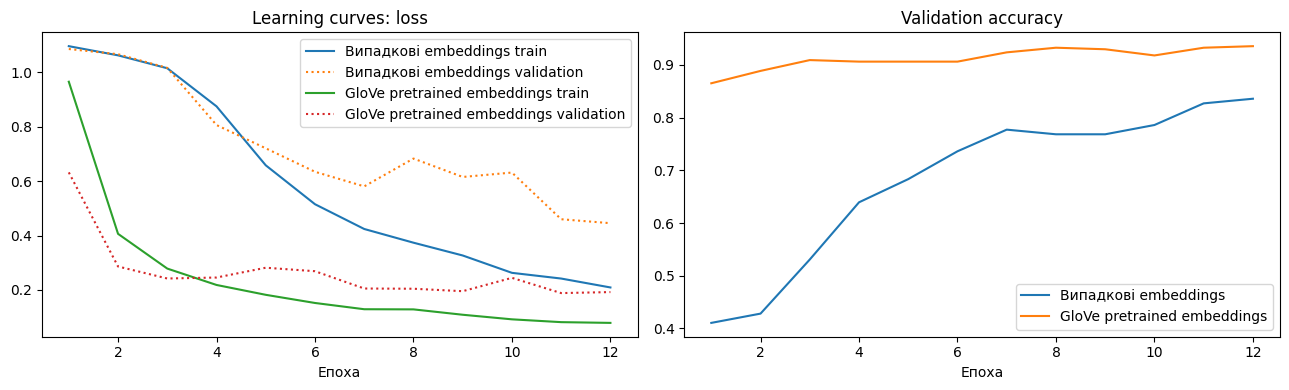

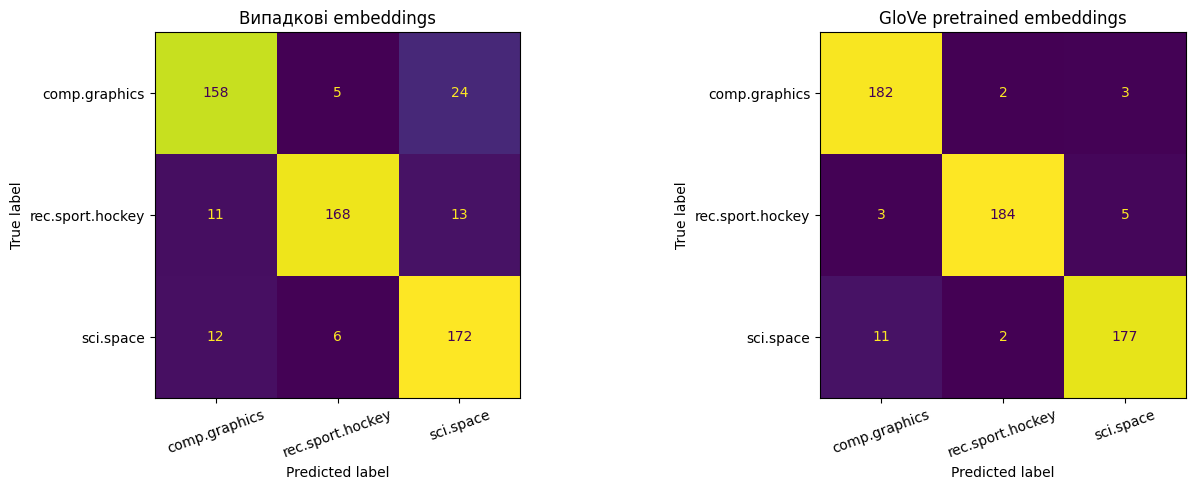

Найкраща текстова модель за accuracy: GloVe pretrained embeddings
                  precision    recall  f1-score   support

   comp.graphics       0.93      0.97      0.95       187
rec.sport.hockey       0.98      0.96      0.97       192
       sci.space       0.96      0.93      0.94       190

        accuracy                           0.95       569
       macro avg       0.95      0.95      0.95       569
    weighted avg       0.95      0.95      0.95       569



**Порівняння BiLSTM.** Випадкова ініціалізація досягла accuracy 87.52% та macro F1 0.876; готові GloVe — accuracy 95.43% та macro F1 0.954. Різниця accuracy = +7.91 в. п. Найменший validation loss у моделях досягнуто відповідно на епохах 12 та 11. Середній час епохи: 7.0 с і 7.0 с.

In [14]:
text_rows, text_predictions_map = [], {}
for name, model, history, elapsed in [
    ('Випадкові embeddings', text_random, history_random, seconds_random),
    ('GloVe pretrained embeddings', text_pretrained, history_pretrained, seconds_pretrained)]:
    predicted = text_predictions(model, test_seq_loader)
    text_predictions_map[name] = predicted
    text_rows.append({'Модель': name,
                      'Test accuracy': accuracy_score(y_test_seq, predicted),
                      'Macro F1': f1_score(y_test_seq, predicted, average='macro'),
                      'Найкраща епоха': int(history.val_loss.idxmin()),
                      'Validation loss': float(history.val_loss.min()),
                      'Середній час епохи': history.seconds.mean(),
                      'Загальний час': elapsed})
result_text = pd.DataFrame(text_rows).set_index('Модель')
display(result_text.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, history in [('Випадкові embeddings', history_random),
                       ('GloVe pretrained embeddings', history_pretrained)]:
    axes[0].plot(history.index, history.train_loss, label=name + ' train')
    axes[0].plot(history.index, history.val_loss, linestyle=':', label=name + ' validation')
    axes[1].plot(history.index, history.val_accuracy, label=name)
axes[0].set_title('Learning curves: loss')
axes[1].set_title('Validation accuracy')
for axis in axes:
    axis.set_xlabel('Епоха')
    axis.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, (name, predictions) in zip(axes, text_predictions_map.items()):
    confusion = confusion_matrix(y_test_seq.numpy(), predictions)
    ConfusionMatrixDisplay(confusion, display_labels=categories).plot(
        ax=axis, values_format='d', colorbar=False, xticks_rotation=20)
    axis.set_title(name)
plt.tight_layout()
plt.show()
print('Найкраща текстова модель за accuracy:', result_text['Test accuracy'].idxmax())
print(classification_report(y_test_seq.numpy(),
      text_predictions_map[result_text['Test accuracy'].idxmax()],
      target_names=categories, zero_division=0))

glove_gain = (result_text.loc['GloVe pretrained embeddings', 'Test accuracy'] -
              result_text.loc['Випадкові embeddings', 'Test accuracy']) * 100
best_rnd = int(history_random.val_loss.idxmin())
best_glove = int(history_pretrained.val_loss.idxmin())
text_analysis = (f'**Порівняння BiLSTM.** Випадкова ініціалізація досягла '
                 f'accuracy {result_text.loc["Випадкові embeddings", "Test accuracy"]:.2%} '
                 f'та macro F1 {result_text.loc["Випадкові embeddings", "Macro F1"]:.3f}; '
                 f'готові GloVe — accuracy '
                 f'{result_text.loc["GloVe pretrained embeddings", "Test accuracy"]:.2%} '
                 f'та macro F1 {result_text.loc["GloVe pretrained embeddings", "Macro F1"]:.3f}. '
                 f'Різниця accuracy = {glove_gain:+.2f} в. п. '
                 f'Найменший validation loss у моделях досягнуто відповідно на епохах '
                 f'{best_rnd} та {best_glove}. '
                 f'Середній час епохи: {history_random.seconds.mean():.1f} с і '
                 f'{history_pretrained.seconds.mean():.1f} с.')
if history_random.val_loss.iloc[-1] > history_random.val_loss.min() + 0.005:
    text_analysis += ' У моделі з випадковими embeddings validation loss наприкінці зростає.'
if history_pretrained.val_loss.iloc[-1] > history_pretrained.val_loss.min() + 0.005:
    text_analysis += ' Для GloVe також є ознаки перенавчання після найкращої епохи.'
display(Markdown(text_analysis))


## Загальні висновки

**Табличні дані.** У MLP дві приховані повнозв'язані ланки та Dropout. Порівняння з SVM і Random Forest виконується за однаковими train/test-вибірками. За learning curves необхідно оцінити, чи продовжує зменшуватися train loss після того, як validation loss досягає мінімуму: у такому разі це ознака перенавчання. Під час тестування використовуються ваги з найменшим validation loss.

**Зображення.** Проста CNN навчається з нуля, а MobileNetV3-Small починає з готових ImageNet-ваг і донавчається на Oxford-IIIT Pet. Порівнюються accuracy, macro F1, швидкість досягнення найкращого validation loss і тривалість навчання. У досліді з 25% і 100% зображень обидві моделі оцінюються на тій самій validation-вибірці. Обмеження порівняння: ImageNet pretraining відбулося до цього експерименту й не включене до виміряного часу.

**Тексти.** Для BiLSTM порівнюється випадкова ініціалізація Embedding з готовими GloVe. Використані однакові послідовності токенів, розбиття даних і архітектура. Прискорення збіжності або покращення якості GloVe оцінюється за фактичними learning curves і тестовими метриками, а не припускається наперед.

Конкретні результати цих експериментів обчислюються і виводяться після запуску клітинок; автоматичний підсумок наведено нижче.

In [15]:
display(Markdown(
    f'**Підсумок отриманих результатів.** На табличних даних найкращу тестову accuracy '
    f'показала модель **{result_tab["Test accuracy"].idxmax()}** '
    f'({result_tab["Test accuracy"].max():.2%}). '
    f'На зображеннях: CNN з нуля — {result_img.loc["CNN з нуля", "accuracy"]:.2%}, '
    f'MobileNetV3 з ImageNet — {result_img.loc["MobileNetV3 (ImageNet)", "accuracy"]:.2%}. '
    f'На текстах: випадкові embeddings — '
    f'{result_text.loc["Випадкові embeddings", "Test accuracy"]:.2%}, '
    f'GloVe — {result_text.loc["GloVe pretrained embeddings", "Test accuracy"]:.2%}. '
    f'Таким чином, перевага pretrained ініціалізації в цих дослідах '
    f'визначається порівнянням фактичних тестових оцінок і кривих навчання, а '
    f'вибір найкращої епохи базується лише на validation loss.'
))

**Підсумок отриманих результатів.** На табличних даних найкращу тестову accuracy показала модель **MLP** (76.84%). На зображеннях: CNN з нуля — 69.28%, MobileNetV3 з ImageNet — 93.76%. На текстах: випадкові embeddings — 87.52%, GloVe — 95.43%. Таким чином, перевага pretrained ініціалізації в цих дослідах визначається порівнянням фактичних тестових оцінок і кривих навчання, а вибір найкращої епохи базується лише на validation loss.